In [5]:
from pycbc.catalog import Merger

merger = Merger("GW150914")
strain_h1 = merger.strain("H1")
strain_l1 = merger.strain("L1")

print("Detector H1:", strain_h1.sample_rate, "Hz,", strain_h1.duration, "seconds")
print("Detector L1:", strain_l1.sample_rate, "Hz,", strain_l1.duration, "seconds")
print("Merger time (GPS):", merger.time)

Detector H1: 4096.0 Hz, 32.0 seconds
Detector L1: 4096.0 Hz, 32.0 seconds
Merger time (GPS): 1126259462.4


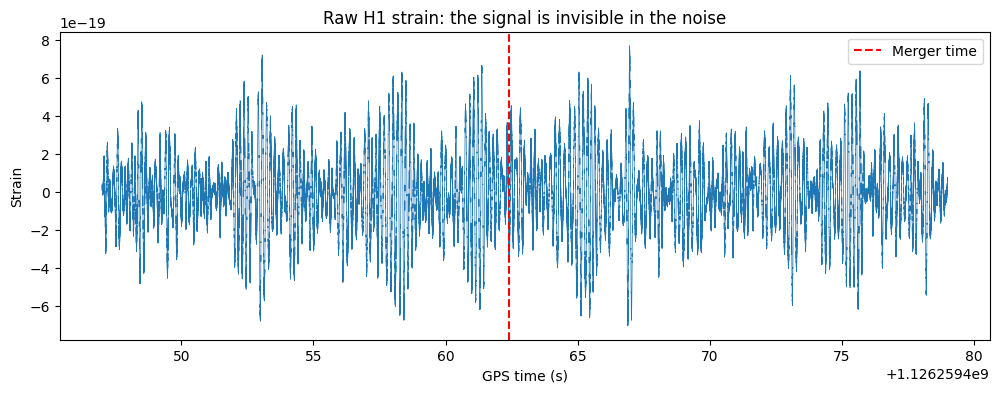

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(strain_h1.sample_times, strain_h1, lw=0.5)
ax.axvline(merger.time, color="red", ls="--", label="Merger time")
ax.set_xlabel("GPS time (s)")
ax.set_ylabel("Strain")
ax.set_title("Raw H1 strain: the signal is invisible in the noise")
ax.legend()
plt.savefig("../outputs/plots/01_raw_strain.png", dpi=200, bbox_inches="tight")
plt.show()

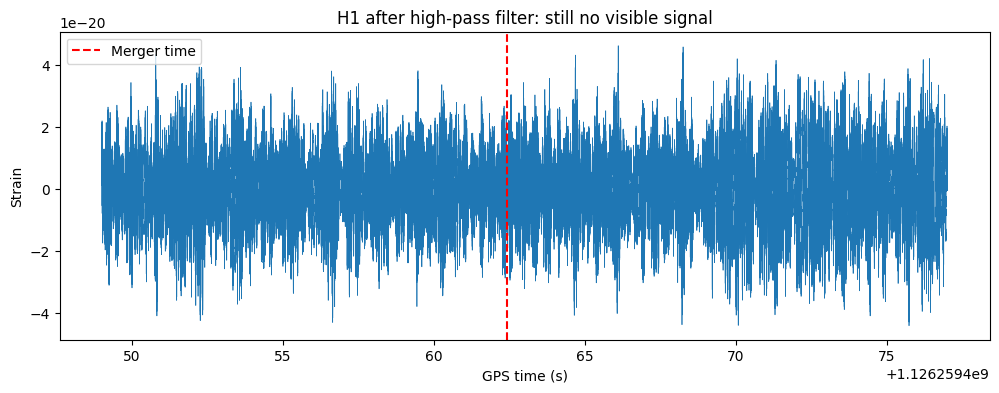

In [7]:
from pycbc.filter import highpass, resample_to_delta_t

def condition(strain):
    s = highpass(strain, 15.0)                 # remove the low-frequency rumble
    s = resample_to_delta_t(s, 1.0/2048)       # 4096 Hz -> 2048 Hz
    return s.crop(2, 2)                        # trim filter edge effects

cond_h1 = condition(strain_h1)
cond_l1 = condition(strain_l1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cond_h1.sample_times, cond_h1, lw=0.5)
ax.axvline(merger.time, color="red", ls="--", label="Merger time")
ax.set_xlabel("GPS time (s)")
ax.set_ylabel("Strain")
ax.set_title("H1 after high-pass filter: still no visible signal")
ax.legend()
plt.savefig("../outputs/plots/02_highpassed_strain.png", dpi=200, bbox_inches="tight")
plt.show()

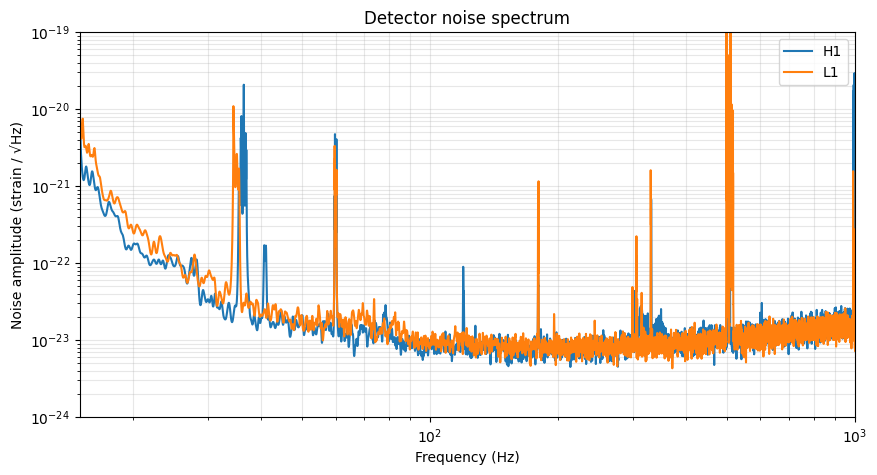

In [8]:
from pycbc.psd import interpolate, inverse_spectrum_truncation

def get_psd(cond):
    psd = cond.psd(4)                                    # average noise power in 4 s chunks
    psd = interpolate(psd, cond.delta_f)
    psd = inverse_spectrum_truncation(
        psd, int(4 * cond.sample_rate), low_frequency_cutoff=15
    )
    return psd

psd_h1 = get_psd(cond_h1)
psd_l1 = get_psd(cond_l1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.loglog(psd_h1.sample_frequencies, psd_h1 ** 0.5, label="H1")
ax.loglog(psd_l1.sample_frequencies, psd_l1 ** 0.5, label="L1")
ax.set_xlim(15, 1000)
ax.set_ylim(1e-24, 1e-19)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Noise amplitude (strain / √Hz)")
ax.set_title("Detector noise spectrum")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.savefig("../outputs/plots/03_noise_spectrum.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
from pycbc.waveform import get_td_waveform
from pycbc.filter import matched_filter

def run_matched_filter(cond, psd, m1=36, m2=31):
    hp, _ = get_td_waveform(approximant="SEOBNRv4_opt",
                            mass1=m1, mass2=m2,
                            delta_t=cond.delta_t, f_lower=20)
    hp.resize(len(cond))
    template = hp.cyclic_time_shift(hp.start_time)
    snr = matched_filter(template, cond, psd=psd, low_frequency_cutoff=20)
    return snr.crop(9, 4), template      # drop edges corrupted by the filter

snr_h1, template = run_matched_filter(cond_h1, psd_h1)
snr_l1, _        = run_matched_filter(cond_l1, psd_l1)

for name, snr in [("H1", snr_h1), ("L1", snr_l1)]:
    i = abs(snr).numpy().argmax()
    print(f"{name}: peak SNR = {abs(snr[i]):.1f} at GPS {snr.sample_times[i]:.3f}")

H1: peak SNR = 17.8 at GPS 1126259462.426
L1: peak SNR = 13.5 at GPS 1126259462.419


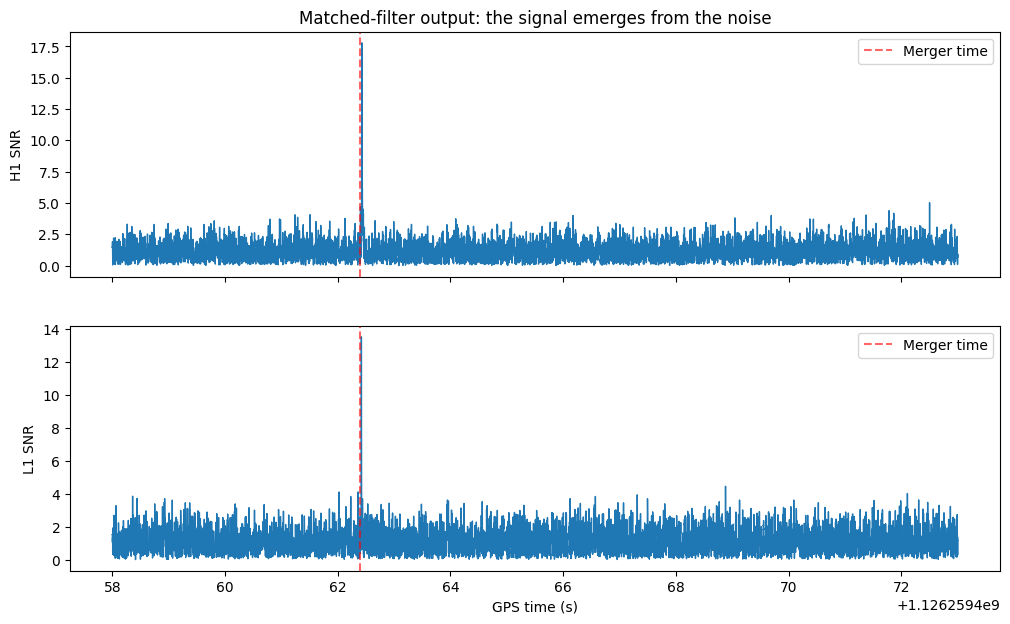

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, snr, name in zip(axes, [snr_h1, snr_l1], ["H1", "L1"]):
    ax.plot(snr.sample_times, abs(snr), lw=1)
    ax.axvline(merger.time, color="red", ls="--", alpha=0.6, label="Merger time")
    ax.set_ylabel(f"{name} SNR")
    ax.legend()
axes[0].set_title("Matched-filter output: the signal emerges from the noise")
axes[1].set_xlabel("GPS time (s)")
plt.savefig("../outputs/plots/04_snr.png", dpi=200, bbox_inches="tight")
plt.show()

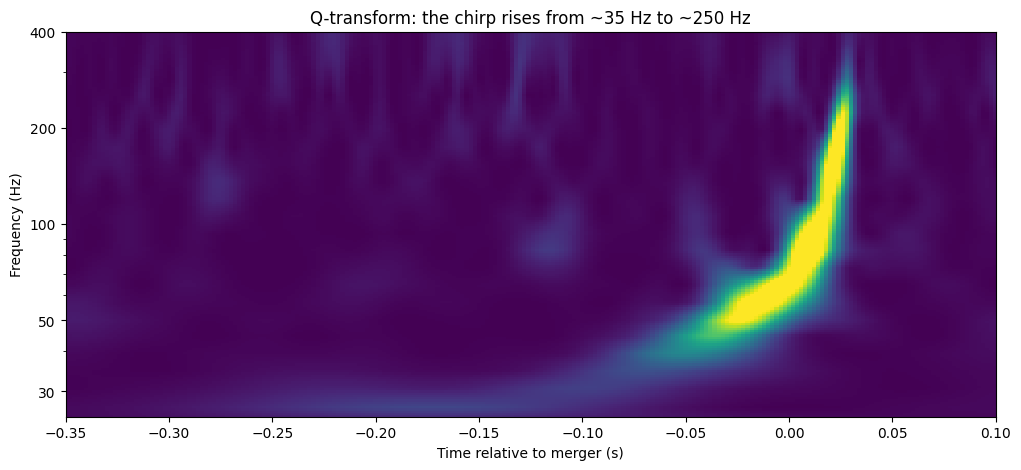

In [14]:
from pycbc.filter import highpass, lowpass_fir, highpass_fir
import numpy as np

def whiten(cond, psd):
    w = (cond.to_frequencyseries() / psd ** 0.5).to_timeseries()
    w = w.highpass_fir(30, 512).lowpass_fir(350, 512)
    return w

white_h1 = whiten(cond_h1, psd_h1)
white_l1 = whiten(cond_l1, psd_l1)

t0 = float(merger.time)
# Use a longer segment, then plot only the middle where edges are clean
seg_long = white_h1.time_slice(t0 - 1.0, t0 + 0.5)
times, freqs, power = seg_long.qtransform(delta_t=0.002, logfsteps=200,
                                          qrange=(8, 8), frange=(20, 500))

# Choose the color scale from the noise, not from the edge blobs
mask = (times - t0 > -0.6) & (times - t0 < 0.3)
vmax = np.percentile(power[:, mask], 99.5)

fig, ax = plt.subplots(figsize=(12, 5))
ax.pcolormesh(times - t0, freqs, power, shading="auto", cmap="viridis",
              vmin=0, vmax=vmax)
ax.set_yscale("log")
ax.set_xlim(-0.35, 0.1)
ax.set_ylim(25, 400)
ax.set_xlabel("Time relative to merger (s)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("Q-transform: the chirp rises from ~35 Hz to ~250 Hz")
ax.set_yticks([30, 50, 100, 200, 400])
ax.set_yticklabels(["30", "50", "100", "200", "400"])
plt.savefig("../outputs/plots/05_chirp.png", dpi=200, bbox_inches="tight")

plt.show()